In [87]:
# REQUIRES, IMPORTS, ETC.
# =======================
# System
# ------
import sys, time, importlib


# Third-party libraries
# ----------------------
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# MODULES
# ========
# System modules
# --------------
from pathlib import Path
from typing import Dict

# Custom types
# ------------
import src.config.ctypes as ctp
importlib.reload(ctp)
from src.config.ctypes import CleanStep, IssueType, IssueAction

# Custom modules
# --------------
from src.config.globals import *

# Helpers functions
# -----------------
import src.helpers.validations as val
importlib.reload(val)
import src.helpers.console as csl
importlib.reload(csl)
import src.helpers.charts as cht
importlib.reload(cht)


<module 'src.helpers.charts' from '/home/dcueli/projects/courses/regulated/ai-and-big-data/p1/bigdata_sys/src/helpers/charts.py'>

In [88]:
# CHECK CHANGES ONF IMPORT FILES
# ==============================
import importlib
importlib.reload(cht)
importlib.reload(val)
importlib.reload(ctp)

print(csl.__file__)
print([name for name in dir(csl)])
print("+ ")

print(cht.__file__)
print([name for name in dir(cht)])
print("+ ")

print(val.__file__)
print([name for name in dir(val)])

/home/dcueli/projects/courses/regulated/ai-and-big-data/p1/bigdata_sys/src/helpers/console.py
['LineBreak', 'SectionBegin', 'SectionBreak', 'SectionEnd', 'SectionErrEndAndExit', '__builtins__', '__cached__', '__doc__', '__file__', '__loader__', '__name__', '__package__', '__spec__', 'nbsp', 'sys', 'time']
+ 
/home/dcueli/projects/courses/regulated/ai-and-big-data/p1/bigdata_sys/src/helpers/charts.py
['BarCht', 'ChartType', 'Dict', 'DifferenceCht', 'DuplicatedCht', 'HistogramCht', 'LineCht', 'PlotSalesAnalytics', 'QualityCht', 'RelationalScatterCht', 'ResidualsScatterCht', 'ScatterCht', 'SequentialScatterCht', 'StripCht', '__builtins__', '__cached__', '__doc__', '__file__', '__loader__', '__name__', '__package__', '__spec__', 'pd', 'plt', 'sns', 'sys', 'val']
+ 
/home/dcueli/projects/courses/regulated/ai-and-big-data/p1/bigdata_sys/src/helpers/validations.py
['Dict', 'ValidateParams', '__builtins__', '__cached__', '__doc__', '__file__', '__loader__', '__name__', '__package__', '__spec__

In [ ]:
# GLOBAL VARIABLES, PATHS
# =======================
# Current file paths
# ------------------
NOTEBOOK_DIR = Path.cwd()
DATA_DIR = (NOTEBOOK_DIR.parent / 'data').resolve()

# Global variables definition for this notebook
# ---------------------------------------------
srcDatasetPath: Path = DATA_DIR / 'ventas_con_problemas.csv'
clnDatasetPath: Path = DATA_DIR / 'ventas_limpias.csv'

# Pandas dataframe to keep save the datasets
dfSrc: pd.DataFrame
dfCln: pd.DataFrame
dfIss: pd.DataFrame

# Algorithm result
res: Dict[str, any]

# Factor for outliers cleaning
iqrFactor: float = 3.0

# Images charts for reports
figPath: Path = DATA_DIR.parent / 'reports' / 'figures'
  

In [90]:
# HELPFUL FUNCTIONS DEFINITIONS
# =============================
# Common function for all notebook
# --------------------------------
# 
# PrintStepSummary
# ----------------
# Filters the central issues tracking DataFrame by a specific pipeline step and 
# prints a standardized audit summary including total issues logged, breakdown 
# by issue type and action, optional verification info, and row count balance.
# 
# @param pd.DataFrame pDfIss      Current issues tracking DataFrame.
# @param CleanStep    pStep       Identifier of the pipeline step to summarize.
# @param int          pRowsBefore Total rows in working DataFrame before the step.
# @param int          pRowsAfter  Total rows in working DataFrame after the step.
# @param str          pTitle      Descriptive label for UI output (default: "Step").
# @param str          pExtraMssg  Optional verification message to print before row balance.
# 
# @return Dict[str, any] Standardized response dictionary with 'bOk' or 'err'.
def PrintStepSummary(
  pDfIss: pd.DataFrame,
  pStep: CleanStep,
  pRowsBefore: int,
  pRowsAfter: int,
  pTitle: str = 'Step',
  pExtraMssg: str = ''
) -> Dict[str, any]:
  # Validate input parameter types before execution
  resVal: Dict[str, any] = val.ValidateParams({
      'pDfIss': (pDfIss, pd.DataFrame),
      'pStep': (pStep, str),
      'pRowsBefore': (pRowsBefore, int),
      'pRowsAfter': (pRowsAfter, int),
      'pTitle': (pTitle, str),
      'pExtraMssg': (pExtraMssg, str)
    },
    sys._getframe(0).f_code.co_name
  )
  if not resVal['bOk']: return resVal

  try:
    # Filter audit records belonging exclusively to the current cleaning step
    dfStepIss: pd.DataFrame = pDfIss[pDfIss['step'] == pStep] if not pDfIss.empty else pd.DataFrame()

    print(f"{pTitle} processed successfully")
    print(f"Total issues logged in '{pStep}': {len(dfStepIss)}")
    print("\nBreakdown by issue type and action:")
    csl.SectionBreak(0, 0)

    if not dfStepIss.empty:
      print(dfStepIss.groupby(['issue_type', 'action']).size())
    else:
      print("No issues logged in this step.")

    if pExtraMssg:
      print(f"\n{pExtraMssg}")

    print(f"Rows before: {pRowsBefore} | Rows after: {pRowsAfter}")

    return {'bOk': True}

  except Exception as e:
    return {
      'bOk': False,
      'err': { 'code': 500, 'whre': sys._getframe(0).f_code.co_name, 'mssg': e.args[0] }
    }

# PrintDataFrame
# --------------
# Prints the content and total row count of a given DataFrame to the console, 
# temporarily overriding Pandas display limits so rows and columns are not truncated.
# Optionally filters by pipeline step if the DataFrame contains a 'step' column,
# or limits the output to the first N rows.
# 
# @param pd.DataFrame     pDf      Target DataFrame to display (e.g., dfIss, dfCln, dfSrc).
# @param str              pTitle   Descriptive header title for UI output (default: 'DataFrame Content').
# @param int | None       pMaxRows Maximum number of rows to print; None prints all rows (default: None).
# @param CleanStep | None pStep    Optional pipeline step filter if inspecting dfIss (default: None).
# 
# @return Dict[str, any] Standardized response dictionary with 'bOk' or 'err'.
def PrintDataFrame(
  pDf: pd.DataFrame,
  pTitle: str = 'DataFrame Content',
  pMaxRows: int | None = None,
  pStep: CleanStep | None = None
) -> Dict[str, any]:
  try:
    dfView: pd.DataFrame = pDf

    # Apply optional step filter if requested and 'step' column exists in DataFrame
    if pStep is not None and 'step' in dfView.columns:
      dfView = dfView[dfView['step'] == pStep]

    print(f"{pTitle} (Total rows: {len(dfView)})")
    csl.SectionBreak(0, 0)

    if dfView.empty:
      print("The DataFrame is empty.")
    else:
      # Temporarily expand Pandas display options to avoid row/column truncation
      with pd.option_context(
        'display.max_rows', None,
        'display.max_columns', None,
        'display.width', 1000,
        'display.expand_frame_repr', False
      ):
        if pMaxRows is not None:
          print(dfView.head(pMaxRows))
        else:
          print(dfView)

    return {'bOk': True}

  except Exception as e:
    return {
      'bOk': False,
      'err': { 'code': 500, 'whre': sys._getframe(0).f_code.co_name, 'mssg': e.args[0] }
    }
# On dfIss
# --------

# LogDataIssues
# -------------
# Appends a subset of affected rows into the central issues tracking DataFrame, 
# attaching metadata about the cleaning step, the specific issue type, and the 
# action performed. Preserves the original row index in 'orig_idx' for traceability.
# 
# @param pd.DataFrame                       pDfIss     Current issues tracking DataFrame.
# @param pd.DataFrame                       pDfRows    Subset of rows exhibiting the data quality issue.
# @param CleanStep                          pStep      Identifier of the pipeline step (e.g., '2_nulls').
# @param IssueType | pd.Series | np.ndarray pIssueType Specific category (or vector of categories) of the problem.
# @param IssueAction                        pAction    Correction strategy applied ('deleted', 'imputed', 'corrected').
#
# # @return Dict[str, Any] Standardized response dictionary with 'bOk' and updated 'data' (pd.DataFrame) or 'err'.
# HELPFUL FUNCTIONS DEFINITIONS
# =============================
def LogDataIssues(
  pDfIss: pd.DataFrame,
  pDfRows: pd.DataFrame,
  pStep: CleanStep,
  pIssueType: IssueType | pd.Series | np.ndarray,
  pAction: IssueAction
) -> Dict[str, any]:

  try:
    # Return current tracking DataFrame unchanged if no rows matched the issue mask
    if pDfRows.empty: return {'bOk': True, 'data': pDfIss}

    # Copy affected rows and attach audit metadata columns
    dfBatch: pd.DataFrame = pDfRows.copy()
    dfBatch['orig_idx'] = dfBatch.index
    dfBatch['step'] = pStep
    dfBatch['issue_type'] = pIssueType
    dfBatch['action'] = pAction

    # Concatenate new batch with existing issues log
    dfUpdated: pd.DataFrame = (
      dfBatch.reset_index(drop=True)
      if pDfIss.empty
      else pd.concat([pDfIss, dfBatch], ignore_index=True)
    )

    return {'bOk': True, 'data': dfUpdated}

  except Exception as e:
    return {
      'bOk': False,
      'err': { 'code': 500, 'whre': sys._getframe(0).f_code.co_name, 'mssg': e.args[0] }
    }


In [91]:
# DATA CLEANING, INITIAL LOAD SOURCE DATASET (from CSV file) AND DATA TYPE STANDARDIZATION
# ========================================================================================
tInit: float = time.time()

# StandarizeTypes
# ---------------
# Normalizes column headers (stripping whitespace and forcing lowercase), and 
# enforces initial base data types on the working DataFrame ('object'/'str' for 
# text columns while preserving NaN values, and 'float64' for numeric columns).
# 
# @param pd.DataFrame pDf Target dataset to be standardized.
# 
# @return Dict[str, any]
def StandarizeTypes(pDf: pd.DataFrame) -> Dict[str, any]:
  # Define column groups by expected data type for standardization
  txtCols: list[str] = ['fecha', 'producto']
  numCols: list[str] = ['cantidad', 'precio_unitario', 'total']

  try:
    # Normalize column names by removing leading/trailing spaces and forcing lowercase
    pDf.columns = pDf.columns.str.strip().str.lower()
    
    # Standardize text columns: strip whitespace only on non-null records to preserve actual NaN values
    for col in txtCols:
      if col in pDf.columns:
        bNotNullMask: pd.Series = pDf[col].notna()
        pDf.loc[bNotNullMask, col] = pDf.loc[bNotNullMask, col].astype(str).str.strip()
            
    # Standardize numeric columns: enforce float64 to support NaN values before step 2 (Null handling)
    for col in numCols:
      if col in pDf.columns:
          pDf[col] = pd.to_numeric(pDf[col], errors='coerce').astype('float64')

    print("Standardized column data types successfully:")
    csl.SectionBreak(0, 0)
    print(pDf.dtypes)

    print("\nSnapshot of rows of the dataset:")
    print(pDf.head(5))

    return {'bOk': True}

  except Exception as e:
    return {
      'bOk': False,
      'err': { 'code': 500, 'whre': sys._getframe(0).f_code.co_name, 'mssg': e.args[0] }
    }

try:
  csl.SectionBegin("DATA CLEANING, LOAD SOURCE (from CSV file)", 0)
  print(f"+ DATASET PATH: \n+ {srcDatasetPath}")
  csl.SectionBreak(0, 0)

  dfSrc = pd.read_csv(srcDatasetPath)
  # Copy the source dataframe to keep the original data and separate from the cleaned data
  dfCln = dfSrc.copy()
  # Initialize empty dataframe to store audit trail of identified data quality issues
  dfIss = pd.DataFrame()

  print(f"File loaded successfully. Total of original rows: {len(dfSrc)}")
  # print(f"Snapshot (5 rows) of the dataset:")
  # csl.nbsp()
  # print(dfSrc.head())
  # csl.SectionBreak(0,0)

  res = StandarizeTypes(dfCln)
  if (not res['bOk']):
    csl.SectionErrEndAndExit(res, tInit)
    
except FileNotFoundError as e:
  csl.SectionErrEndAndExit({
      'bOk': False,
      'err': { 'code': 500, 'whre': sys._getframe(0).f_code.co_name, 'mssg': e.args[0] }
    }, tInit)
  
csl.SectionBreak(0,0)
tEnd: float = time.time()
print(f"+ Time to load: {tEnd - tInit:.4f} seconds")
csl.SectionEnd(0)


+ =========================================================
+ DATA CLEANING, LOAD SOURCE (from CSV file)
+ DATASET PATH: 
+ /home/dcueli/projects/courses/regulated/ai-and-big-data/p1/bigdata_sys/src/activities/RA1/lesson_02/data/ventas_con_problemas.csv
+ ---------------------------------------------------------
File loaded successfully. Total of original rows: 320
Standardized column data types successfully:
+ ---------------------------------------------------------
fecha                  str
producto               str
cantidad           float64
precio_unitario    float64
total              float64
dtype: object

Snapshot of rows of the dataset:
  fecha             producto  cantidad  precio_unitario   total
0   NaN  Monitor 24 pulgadas       1.0           114.18  114.18
1   NaN      Cargador rapido       6.0            37.74  226.44
2   NaN  Monitor 24 pulgadas       5.0           193.91  969.55
3   NaN     Altavoz portatil       8.0           111.84  894.72
4   NaN      Cargador ra

In [92]:
# DATA CLEANING, 2. NULL VALUES MANAGEMENT
# ========================================
tInit: float = time.time()

csl.SectionBegin("DATA CLEANING, NULL VALUES MANAGEMENT", 0)
csl.SectionBreak(0, 0)

rowsBeforeNulls: int = 0

try:
    rowsBeforeNulls = len(dfCln)

    # 1. Identify, log, and exclude rows with nulls in non-recoverable critical fields ('fecha', 'producto')
    bCritNullMask: pd.Series = dfCln['fecha'].isna() | dfCln['producto'].isna()
    res = LogDataIssues(dfIss, dfCln.loc[bCritNullMask], '2_nulls', 'null_critical', 'deleted')
    if not res['bOk']: raise Exception(res['err']['mssg'])
    dfIss = res['data']
    dfCln = dfCln.loc[~bCritNullMask].copy()

    # 2. Deterministic imputation for numeric fields using: total = cantidad * precio_unitario
    # 2.a Identify, log, and recover missing 'cantidad' where 'total' and 'precio_unitario' are valid
    bQtyNullMask: pd.Series = (
      dfCln['cantidad'].isna() & 
      dfCln['total'].notna() & 
      dfCln['precio_unitario'].notna() & 
      (dfCln['precio_unitario'] != 0)
    )
    res = LogDataIssues(dfIss, dfCln.loc[bQtyNullMask], '2_nulls', 'null_cantidad', 'imputed')
    if not res['bOk']: raise Exception(res['err']['mssg'])
    dfIss = res['data']
    dfCln.loc[bQtyNullMask, 'cantidad'] = (
      dfCln.loc[bQtyNullMask, 'total'] / dfCln.loc[bQtyNullMask, 'precio_unitario']
    ).round(0)

    # 2.b Identify, log, and recover missing 'precio_unitario' where 'total' and 'cantidad' are valid
    bPriceNullMask: pd.Series = (
      dfCln['precio_unitario'].isna() & 
      dfCln['total'].notna() & 
      dfCln['cantidad'].notna() & 
      (dfCln['cantidad'] != 0)
    )
    res = LogDataIssues(dfIss, dfCln.loc[bPriceNullMask], '2_nulls', 'null_precio_unitario', 'imputed')
    if not res['bOk']: raise Exception(res['err']['mssg'])
    dfIss = res['data']
    dfCln.loc[bPriceNullMask, 'precio_unitario'] = (
      dfCln.loc[bPriceNullMask, 'total'] / dfCln.loc[bPriceNullMask, 'cantidad']
    ).round(2)

    # 2.c Identify, log, and recover missing 'total' where 'cantidad' and 'precio_unitario' are valid
    bTotalNullMask: pd.Series = (
      dfCln['total'].isna() & 
      dfCln['cantidad'].notna() & 
      dfCln['precio_unitario'].notna()
    )
    res = LogDataIssues(dfIss, dfCln.loc[bTotalNullMask], '2_nulls', 'null_total', 'imputed')
    if not res['bOk']: raise Exception(res['err']['mssg'])
    dfIss = res['data']
    dfCln.loc[bTotalNullMask, 'total'] = (
      dfCln.loc[bTotalNullMask, 'cantidad'] * dfCln.loc[bTotalNullMask, 'precio_unitario']
    ).round(2)

    # 3. Fallback exclusion: log and drop any remaining rows if multiple numeric fields were null simultaneously
    bRemNullMask: pd.Series = dfCln.isna().any(axis=1)
    if bRemNullMask.any():
      res = LogDataIssues(dfIss, dfCln.loc[bRemNullMask], '2_nulls', 'null_multiple_numeric', 'deleted')
      if not res['bOk']: raise Exception(res['err']['mssg'])
      dfIss = res['data']
      dfCln = dfCln.loc[~bRemNullMask].copy()

    # Display summary from the audit DataFrame for this cleaning step
    res = PrintStepSummary(
      dfIss,
      '2_nulls',
      rowsBeforeNulls,
      len(dfCln),
      "Null values",
      f"Remaining nulls in cleaned dataset: {int(dfCln.isna().sum().sum())}"
    )
    if not res['bOk']: raise Exception(res['err']['mssg'])

except Exception as e:
  csl.SectionErrEndAndExit({
      'bOk': False,
      'err': { 'code': 500, 'whre': sys._getframe(0).f_code.co_name, 'mssg': e.args[0] }
    }, tInit)

csl.SectionBreak(0,0)
tEnd: float = time.time()
print(f"+ Time to load: {tEnd - tInit:.4f} seconds")
csl.SectionEnd(0)

+ =========================================================
+ DATA CLEANING, NULL VALUES MANAGEMENT
+ ---------------------------------------------------------
Null values processed successfully
Total issues logged in '2_nulls': 25

Breakdown by issue type and action:
+ ---------------------------------------------------------
issue_type            action 
null_cantidad         imputed     5
null_critical         deleted    10
null_precio_unitario  imputed     5
null_total            imputed     5
dtype: int64

Remaining nulls in cleaned dataset: 0
Rows before: 320 | Rows after: 310
+ ---------------------------------------------------------
+ Time to load: 0.0251 seconds
+ =========================================================


In [93]:
# DATA CLEANING, 3. DUPLICATE ROWS REMOVAL
# ========================================
tInit: float = time.time()


try:
  csl.SectionBegin("DATA CLEANING, DUPLICATE ROWS REMOVAL", 0)
  csl.SectionBreak(0, 0)

  rowsBeforeDupl: int = 0
  keyCols: list[str] = ['fecha', 'producto', 'cantidad', 'precio_unitario', 'total']
  rowsBeforeDupl = len(dfCln)

  # Identify redundant duplicate rows keeping the first valid occurrence ('keep=first')
  bDuplMask: pd.Series = dfCln.duplicated(subset=keyCols, keep='first')

  # Log the 12 redundant duplicate rows into the audit DataFrame before removal
  res = LogDataIssues(dfIss, dfCln.loc[bDuplMask], '3_duplicates', 'duplicate_row', 'deleted')
  if not res['bOk']: raise Exception(res['err']['mssg'])
  dfIss = res['data']

  # Remove duplicate rows from the working clean DataFrame
  dfCln = dfCln.loc[~bDuplMask].copy()

  # Display summary from the audit DataFrame for Step 3
  res = PrintStepSummary(
    dfIss,
    '3_duplicates',
    rowsBeforeDupl,
    len(dfCln),
    "Duplicate rows",
    f"Remaining duplicates in dfCln: {int(dfCln.duplicated(subset=keyCols).sum())}"
  )
  if not res['bOk']: raise Exception(res['err']['mssg'])

except Exception as e:
  csl.SectionErrEndAndExit({
    'bOk': False,
    'err': { 'code': 500, 'whre': sys._getframe(0).f_code.co_name, 'mssg': e.args[0] }
  }, tInit)
  
csl.SectionBreak(0,0)
tEnd: float = time.time()
print(f"+ Time to load: {tEnd - tInit:.4f} seconds")
csl.SectionEnd(0)


+ =========================================================
+ DATA CLEANING, DUPLICATE ROWS REMOVAL
+ ---------------------------------------------------------
Duplicate rows processed successfully
Total issues logged in '3_duplicates': 12

Breakdown by issue type and action:
+ ---------------------------------------------------------
issue_type     action 
duplicate_row  deleted    12
dtype: int64

Remaining duplicates in dfCln: 0
Rows before: 310 | Rows after: 298
+ ---------------------------------------------------------
+ Time to load: 0.0110 seconds
+ =========================================================


In [94]:
# DATA CLEANING, 4. INVALID NUMERICS AND TOTALS CORRECTION
# ========================================================
tInit: float = time.time()

try:
  csl.SectionBegin("DATA CLEANING, INVALID NUMERICS AND TOTALS CORRECTION", 0)
  csl.SectionBreak(0, 0)

  rowsBeforeTotals: int = len(dfCln)

  # 1. Identify, log, and remove rows with zero values in numeric columns (if any)
  bZeroMask: pd.Series = (
    (0 == dfCln['cantidad']) | 
    (0 == dfCln['precio_unitario']) | 
    (0 == dfCln['total'])
  )
 
  res = LogDataIssues(dfIss, dfCln.loc[bZeroMask], '4_invalid_numerics', 'zero_value', 'deleted')

  if not res['bOk']: raise Exception(res['err']['mssg'])

  dfIss = res['data']
  dfCln = dfCln.loc[~bZeroMask].copy()

  # 2. Identify, log, and remove rows with negative values following sales department guidelines
  bNegMask: pd.Series = (
    (0 > dfCln['cantidad']) | 
    (0 > dfCln['precio_unitario']) | 
    (0 > dfCln['total'])
  )
  
  res = LogDataIssues(dfIss, dfCln.loc[bNegMask], '4_invalid_numerics', 'negative_value', 'deleted')
  
  if not res['bOk']: raise Exception(res['err']['mssg'])
  
  dfIss = res['data']
  dfCln = dfCln.loc[~bNegMask].copy()

  # 3. Identify, log, and recalculate inconsistent totals (cantidad * precio_unitario != total)
  expectedTotal: pd.Series = (dfCln['cantidad'] * dfCln['precio_unitario']).round(2)
  bMismatchMask: pd.Series = (expectedTotal - dfCln['total'].round(2)).abs() > 0.01

  res = LogDataIssues(dfIss, dfCln.loc[bMismatchMask], '4_invalid_numerics', 'total_mismatch', 'corrected')
  
  if not res['bOk']: raise Exception(res['err']['mssg'])
  
  dfIss = res['data']

  # Overwrite inconsistent totals with the exact product of 'cantidad' and 'precio_unitario'
  dfCln.loc[bMismatchMask, 'total'] = expectedTotal.loc[bMismatchMask]

  # Display standardized audit summary for Step 4
  remInvalidNum: int = int(((dfCln['cantidad'] <= 0) | (dfCln['precio_unitario'] <= 0) | (dfCln['total'] <= 0)).sum())
  remMism: int = int(((dfCln['cantidad'] * dfCln['precio_unitario']).round(2) != dfCln['total'].round(2)).sum())
  res = PrintStepSummary(
    dfIss,
    '4_invalid_numerics',
    rowsBeforeTotals,
    len(dfCln),
    'Invalid numerics and totals',
    f"Remaining negative/zero rows: {remInvalidNum} | Remaining total mismatches: {remMism}"
  )
  
  if not res['bOk']: raise Exception(res['err']['mssg'])

except Exception as e:
  csl.SectionErrEndAndExit({
    'bOk': False,
    'err': { 'code': 500, 'whre': sys._getframe(0).f_code.co_name, 'mssg': e.args[0] }
  }, tInit)

csl.SectionBreak(0, 0)
tEnd: float = time.time()
print(f"+ Time to process: {tEnd - tInit:.4f} seconds")
csl.SectionEnd(0)

+ =========================================================
+ DATA CLEANING, INVALID NUMERICS AND TOTALS CORRECTION
+ ---------------------------------------------------------
Invalid numerics and totals processed successfully
Total issues logged in '4_invalid_numerics': 55

Breakdown by issue type and action:
+ ---------------------------------------------------------
issue_type      action   
negative_value  deleted      30
total_mismatch  corrected    25
dtype: int64

Remaining negative/zero rows: 0 | Remaining total mismatches: 0
Rows before: 298 | Rows after: 268
+ ---------------------------------------------------------
+ Time to process: 0.0155 seconds
+ =========================================================


In [95]:
# DATA CLEANING, 5. INVALID DATES TREATMENT
# =========================================
tInit: float = time.time()

try:
  csl.SectionBegin("DATA CLEANING, INVALID DATES TREATMENT", 0)
  csl.SectionBreak(0, 0)

  rowsBeforeDates: int = len(dfCln)

  # Define valid 30-day sales window boundaries according to business requirements
  minValidDate: pd.Timestamp = pd.Timestamp('2026-09-19')
  maxValidDate: pd.Timestamp = pd.Timestamp('2026-10-18')

  # Parse 'fecha' enforcing ISO format (YYYY-MM-DD); corrupt or impossible calendar dates become NaT
  parsedDates: pd.Series = pd.to_datetime(dfCln['fecha'], format='%Y-%m-%d', errors='coerce')

  # Identify rows where date parsing failed (NaT) or falls outside the valid 30-day window
  bInvalidDateMask: pd.Series = (
    parsedDates.isna() | 
    (parsedDates < minValidDate) | 
    (parsedDates > maxValidDate)
  )

  # Log invalid or out-of-range date records into the audit DataFrame before removal
  res = LogDataIssues(dfIss, dfCln.loc[bInvalidDateMask], '5_dates', 'invalid_date', 'deleted')
  if not res['bOk']: raise Exception(res['err']['mssg'])
  dfIss = res['data']

  # Exclude invalid date rows and enforce datetime64[ns] type on the remaining valid records
  dfCln = dfCln.loc[~bInvalidDateMask].copy()
  dfCln['fecha'] = parsedDates.loc[~bInvalidDateMask]

  # Display standardized audit summary for Step 5
  remInvalidDates: int = int(dfCln['fecha'].isna().sum())
  res = PrintStepSummary(
    dfIss,
    '5_dates',
    rowsBeforeDates,
    len(dfCln),
    'Invalid dates',
    f"Remaining invalid dates in dfCln: {remInvalidDates} | Column 'fecha' dtype: {dfCln['fecha'].dtype}"
  )
  if not res['bOk']: raise Exception(res['err']['mssg'])

except Exception as e:
  csl.SectionErrEndAndExit({
    'bOk': False,
    'err': { 'code': 500, 'whre': sys._getframe(0).f_code.co_name, 'mssg': e.args[0] }
  }, tInit)

csl.SectionBreak(0, 0)
tEnd: float = time.time()
print(f"+ Time to process: {tEnd - tInit:.4f} seconds")
csl.SectionEnd(0)

+ =========================================================
+ DATA CLEANING, INVALID DATES TREATMENT
+ ---------------------------------------------------------
Invalid dates processed successfully
Total issues logged in '5_dates': 13

Breakdown by issue type and action:
+ ---------------------------------------------------------
issue_type    action 
invalid_date  deleted    13
dtype: int64

Remaining invalid dates in dfCln: 0 | Column 'fecha' dtype: datetime64[us]
Rows before: 268 | Rows after: 255
+ ---------------------------------------------------------
+ Time to process: 0.0107 seconds
+ =========================================================


In [96]:
# DATA CLEANING, 6. OUTLIERS FILTERING
# ====================================
tInit: float = time.time()

try:
  csl.SectionBegin("DATA CLEANING, OUTLIERS FILTERING (IQR METHOD)", 0)
  csl.SectionBreak(0, 0)

  rowsBeforeOutliers: int = len(dfCln)

  # 1. Calculate IQR boundaries for 'cantidad'
  q1Qty: float = float(dfCln['cantidad'].quantile(0.25))
  q3Qty: float = float(dfCln['cantidad'].quantile(0.75))
  iqrQty: float = q3Qty - q1Qty
  lowBoundQty: float = q1Qty - iqrFactor * iqrQty
  highBoundQty: float = q3Qty + iqrFactor * iqrQty

  # 2. Calculate IQR boundaries for 'precio_unitario'
  q1Price: float = float(dfCln['precio_unitario'].quantile(0.25))
  q3Price: float = float(dfCln['precio_unitario'].quantile(0.75))
  iqrPrice: float = q3Price - q1Price
  lowBoundPrice: float = q1Price - iqrFactor * iqrPrice
  highBoundPrice: float = q3Price + iqrFactor * iqrPrice

  print(f"IQR bounds for 'cantidad':       [{lowBoundQty:.2f}, {highBoundQty:.2f}]")
  print(f"IQR bounds for 'precio_unitario': [{lowBoundPrice:.2f}, {highBoundPrice:.2f}]")
  csl.SectionBreak(0, 0)

  # 3. Build boolean masks for outliers in each primary numeric column
  bRawOutQty: pd.Series = (dfCln['cantidad'] < lowBoundQty) | (dfCln['cantidad'] > highBoundQty)
  bRawOutPrice: pd.Series = (dfCln['precio_unitario'] < lowBoundPrice) | (dfCln['precio_unitario'] > highBoundPrice)

  # Mutually exclusive masks for accurate audit categorization
  bOutBothMask: pd.Series = bRawOutQty & bRawOutPrice
  bOutQtyMask: pd.Series = bRawOutQty & (~bRawOutPrice)
  bOutPriceMask: pd.Series = (~bRawOutQty) & bRawOutPrice
  bAnyOutlierMask: pd.Series = bRawOutQty | bRawOutPrice

  # 4. Log identified outliers into the central audit DataFrame by specific category
  outlierTypes: np.ndarray = np.select([
      bRawOutQty.loc[bAnyOutlierMask] & bRawOutPrice.loc[bAnyOutlierMask],
      bRawOutQty.loc[bAnyOutlierMask]
    ], [
      'outlier_both',
      'outlier_cantidad'
    ],
    default='outlier_precio_unitario'
  )

  res = LogDataIssues(dfIss, dfCln.loc[bAnyOutlierMask], '6_outliers', outlierTypes, 'deleted')
  if not res['bOk']: raise Exception(res['err']['mssg'])
  dfIss = res['data']

  # 5. Exclude all identified outlier rows from the clean working DataFrame
  dfCln = dfCln.loc[~bAnyOutlierMask].copy()

  # Display standardized audit summary for Step 6
  res = PrintStepSummary(
    dfIss,
    '6_outliers',
    rowsBeforeOutliers,
    len(dfCln),
    'Outliers filtering',
    f"Max 'cantidad' after filtering: {dfCln['cantidad'].max():.0f} \nMax 'precio_unitario' after filtering: {dfCln['precio_unitario'].max():.2f}\n"
  )
  if not res['bOk']: raise Exception(res['err']['mssg'])

except Exception as e:
  csl.SectionErrEndAndExit({
    'bOk': False,
    'err': { 'code': 500, 'whre': sys._getframe(0).f_code.co_name, 'mssg': e.args[0] }
  }, tInit)

csl.SectionBreak(0, 0)
tEnd: float = time.time()
print(f"+ Time to process: {tEnd - tInit:.4f} seconds")
csl.SectionEnd(0)

+ =========================================================
+ DATA CLEANING, OUTLIERS FILTERING (IQR METHOD)
+ ---------------------------------------------------------
IQR bounds for 'cantidad':       [-8.00, 13.00]
IQR bounds for 'precio_unitario': [-186.62, 309.54]
+ ---------------------------------------------------------
Outliers filtering processed successfully
Total issues logged in '6_outliers': 22

Breakdown by issue type and action:
+ ---------------------------------------------------------
issue_type               action 
outlier_both             deleted    6
outlier_cantidad         deleted    8
outlier_precio_unitario  deleted    8
dtype: int64

Max 'cantidad' after filtering: 8 
Max 'precio_unitario' after filtering: 247.86

Rows before: 255 | Rows after: 233
+ ---------------------------------------------------------
+ Time to process: 0.0169 seconds
+ =========================================================


In [97]:
# DATA CLEANING, 7. FINAL VALIDATION AND EXPORT (to CSV file)
# ===========================================================
tInit: float = time.time()

try:
  csl.SectionBegin("DATA CLEANING, FINAL VALIDATION AND EXPORT", 0)
  csl.SectionBreak(0, 0)

  # 1. Enforce final integer data type on 'cantidad' now that all NaN values are resolved
  dfCln['cantidad'] = dfCln['cantidad'].round(0).astype('int64')
  dfCln['precio_unitario'] = dfCln['precio_unitario'].round(2)
  dfCln['total'] = dfCln['total'].round(2)

  # Reset index to a clean sequential range [0 .. N-1]
  dfCln = dfCln.reset_index(drop=True)

  # 2. Final quality gate assertions before exporting to disk
  keyCols: list[str] = ['fecha', 'producto', 'cantidad', 'precio_unitario', 'total']
  remNulls: int = int(dfCln.isna().sum().sum())
  remDupls: int = int(dfCln.duplicated(subset=keyCols).sum())
  remInvNum: int = int(((dfCln['cantidad'] <= 0) | (dfCln['precio_unitario'] <= 0) | (dfCln['total'] <= 0)).sum())
  remMism: int = int(((dfCln['cantidad'] * dfCln['precio_unitario']).round(2) != dfCln['total'].round(2)).sum())

  if 0 < remNulls or 0 < remDupls or 0 < remInvNum or 0 < remMism:
    raise Exception(
      f"Quality gate failed -> Nulls: {remNulls}, Duplicates: {remDupls}, "
      f"Invalid numerics: {remInvNum}, Total mismatches: {remMism}"
    )

  # 3. Export cleaned dataset to CSV without index column
  dfCln.to_csv(clnDatasetPath, index=False, encoding='utf-8', date_format='%Y-%m-%d')

  print("Final validation passed and dataset exported successfully")
  print(f"Exported file path:\n{clnDatasetPath}")
  csl.SectionBreak(0, 0)
  print("Final column data types in dfCln:")
  print(dfCln.dtypes)
  csl.SectionBreak(0, 0)
  print(f"Original rows (dfSrc):              {len(dfSrc)}")
  print(f"Final clean rows (dfCln):           {len(dfCln)}")
  print(f"Total rows removed:                 {len(dfSrc) - len(dfCln)} ({((len(dfSrc) - len(dfCln)) / len(dfSrc)) * 100:.2f}%)")
  print(f"Total issues logged in audit trail: {len(dfIss)}")
  print("\nSnapshot (5 rows) of the final clean dataset:")
  print(dfCln.head(5))

except Exception as e:
  csl.SectionErrEndAndExit({
    'bOk': False,
    'err': { 'code': 500, 'whre': sys._getframe(0).f_code.co_name, 'mssg': e.args[0] }
  }, tInit)

csl.SectionBreak(0, 0)
tEnd: float = time.time()
print(f"+ Time to process: {tEnd - tInit:.4f} seconds")
csl.SectionEnd(0)

+ =========================================================
+ DATA CLEANING, FINAL VALIDATION AND EXPORT
+ ---------------------------------------------------------
Final validation passed and dataset exported successfully
Exported file path:
/home/dcueli/projects/courses/regulated/ai-and-big-data/p1/bigdata_sys/src/activities/RA1/lesson_02/data/ventas_limpias.csv
+ ---------------------------------------------------------
Final column data types in dfCln:
fecha              datetime64[us]
producto                      str
cantidad                    int64
precio_unitario           float64
total                     float64
dtype: object
+ ---------------------------------------------------------
Original rows (dfSrc):              320
Final clean rows (dfCln):           233
Total rows removed:                 87 (27.19%)
Total issues logged in audit trail: 127

Snapshot (5 rows) of the final clean dataset:
       fecha               producto  cantidad  precio_unitario   total
0 2026-10

In [ ]:
# REPORTS: 1. ORIGINAL ROWS VS. CLEAN ROWS
# ========================================
tInit: float = time.time()

try:
  csl.SectionBegin("REPORTS, 1. ORIGINAL VS. CLEAN ROWS", 0)
  csl.SectionBreak(0, 0)

  origRows: int = len(dfSrc)
  cleanRows: int = len(dfCln)
  removedRows: int = origRows - cleanRows
  retainedPct: float = (cleanRows / origRows) * 100.0
  removedPct: float = (removedRows / origRows) * 100.0

  print("VOLUME COMPARISON (ORIGINAL ROWS VS. CLEANED ROWS)")
  csl.SectionBreak(0, 0)
  print(f"Original rows (dfSrc dataset):        {origRows}")
  print(f"Rows after cleaning (dfCln datast):  {cleanRows} ({retainedPct:.2f}% retenidas)")
  print(f"Deleted rows:  {removedRows} ({removedPct:.2f}% del total)")

except Exception as e:
  csl.SectionErrEndAndExit({
    'bOk': False,
    'err': {
      'code': 500,
      'whre': sys._getframe(0).f_code.co_name,
      'mssg': e.args[0]
    }
  }, tInit)

csl.SectionBreak(0, 0)
tEnd: float = time.time()
print(f"+ Time to process: {tEnd - tInit:.4f} seconds")
csl.SectionEnd(0)

+ =========================================================
+ REPORTS, 1. ORIGINAL VS. CLEAN ROWS
+ ---------------------------------------------------------
VOLUME COMPARISON (ORIGINAL ROWS VS. CLEANED ROWS)
+ ---------------------------------------------------------
Original rows (dfSrc dataset):        320
Rows after cleaning (dfCln datast):  233 (72.81% retenidas)
Deleted rows:  87 (27.19% del total)
+ ---------------------------------------------------------
+ Time to process: 0.0008 seconds
+ =========================================================


In [ ]:
# REPORTS: 2. ISSUES BY TYPE
# ==========================
tInit: float = time.time()

try:
  csl.SectionBegin("REPORTS, 2. ISSUES BY TYPE", 0)
  csl.SectionBreak(0, 0)

  totalIssues: int = len(dfIss)

  print("IDENTIFIED AND RESOLVED ISSUES BREAKDOWN")
  csl.SectionBreak(0, 0)
  
  # Group audit records by step, issue type, and action
  dfIssuesSummary: pd.DataFrame = (
    dfIss.groupby(['step', 'issue_type', 'action'])
    .size()
    .unstack(fill_value=0)
  )
  dfIssuesSummary['total'] = dfIssuesSummary.sum(axis=1)

  res = PrintDataFrame(dfIssuesSummary, "Issues Summary Breakdown by Step and Action")
  if not res['bOk']: raise Exception(res['err']['mssg'])

  csl.SectionBreak(0, 0)
  print(f"Total audit issues recorded in dfIss: {totalIssues}")

except Exception as e:
  csl.SectionErrEndAndExit({
    'bOk': False,
    'err': {
      'code': 500,
      'whre': sys._getframe(0).f_code.co_name,
      'mssg': e.args[0]
    }
  }, tInit)

csl.SectionBreak(0, 0)
tEnd: float = time.time()
print(f"+ Time to process: {tEnd - tInit:.4f} seconds")
csl.SectionEnd(0)

+ =========================================================
+ REPORTS, 2. ISSUES BY TYPE
+ ---------------------------------------------------------
IDENTIFIED AND RESOLVED ISSUES BREAKDOWN
+ ---------------------------------------------------------
Issues Summary Breakdown by Step and Action (Total rows: 11)
+ ---------------------------------------------------------
action                                      corrected  deleted  imputed  total
step               issue_type                                                 
2_nulls            null_cantidad                    0        0        5      5
                   null_critical                    0       10        0     10
                   null_precio_unitario             0        0        5      5
                   null_total                       0        0        5      5
3_duplicates       duplicate_row                    0       12        0     12
4_invalid_numerics negative_value                   0       30        0     

In [104]:
# REPORTS: 3, DESCRIPTIVE STATISTICS OF CLEANED NUMERIC FIELDS
# ============================================================
tInit: float = time.time()

try:
  csl.SectionBegin("REPORTS: 3, DESCRIPTIVE STATISTICS OF CLEANED NUMERIC FIELDS", 0)
  csl.SectionBreak(0, 0)

  print("DESCRIPTIVE STATISTICS OF NUMERIC FIELDS")
  csl.SectionBreak(0, 0)

  numCols: list[str] = ['cantidad', 'precio_unitario', 'total']
  dfStatsClean: pd.DataFrame = (
    dfCln[numCols]
    .agg(['count', 'mean', 'median', 'std', 'min', 'max'])
    .T
    .round(2)
  )
  dfStatsClean['count'] = dfStatsClean['count'].astype('int64')

  res = PrintDataFrame(dfStatsClean, "Cleaned Dataset Descriptive Statistics")
  if not res['bOk']: raise Exception(res['err']['mssg'])

except Exception as e:
  csl.SectionErrEndAndExit({
    'bOk': False,
    'err': { 'code': 500, 'whre': sys._getframe(0).f_code.co_name, 'mssg': e.args[0] }
  }, tInit)

csl.SectionBreak(0, 0)
tEnd: float = time.time()
print(f"+ Time to process: {tEnd - tInit:.4f} seconds")
csl.SectionEnd(0)

+ =========================================================
+ REPORTS: 3, DESCRIPTIVE STATISTICS OF CLEANED NUMERIC FIELDS
+ ---------------------------------------------------------
DESCRIPTIVE STATISTICS OF NUMERIC FIELDS
+ ---------------------------------------------------------
Cleaned Dataset Descriptive Statistics (Total rows: 3)
+ ---------------------------------------------------------
                 count    mean  median     std   min      max
cantidad           233    2.45    2.00    1.66  1.00     8.00
precio_unitario    233   60.44   48.18   46.07  5.04   247.86
total              233  153.24   88.60  176.98  6.27  1115.73
+ ---------------------------------------------------------
+ Time to process: 0.0122 seconds
+ =========================================================


In [110]:
# DATA CLEANING, 8 SUMMARY REPORTS ABOVE 1,2 & 3
# ==============================================
tInit: float = time.time()

try:
  csl.SectionBegin("DATA CLEANING, 8 SUMMARY REPORTS ABOVE 1,2 & 3", 0)
  csl.SectionBreak(0, 0)

  # 1. Original rows vs. clean rows balance
  origRows: int = len(dfSrc)
  cleanRows: int = len(dfCln)
  removedRows: int = origRows - cleanRows
  retainedPct: float = (cleanRows / origRows) * 100.0
  removedPct: float = (removedRows / origRows) * 100.0
  totalIssues: int = len(dfIss)

  print("1. DATASET VOLUME BALANCE (ORIGINAL VS. CLEANED)")
  csl.SectionBreak(0, 0)
  print(f"Original rows (dfSrc):          {origRows}")
  print(f"Cleaned rows (dfCln):           {cleanRows} ({retainedPct:.2f}% retained)")
  print(f"Total rows removed:             {removedRows} ({removedPct:.2f}% discarded)")
  print(f"Total data issues audited:      {totalIssues}")
  print("\nGlobal breakdown by resolution action:")
  print(dfIss['action'].value_counts().to_string())
  csl.SectionBreak(0, 0)

  # 2. Quantity of identified and resolved issues by step, type, and action
  print("2. IDENTIFIED AND RESOLVED ISSUES BY CATEGORY")
  csl.SectionBreak(0, 0)
  dfIssuesSummary: pd.DataFrame = (
    dfIss.groupby(['step', 'issue_type', 'action'])
    .size()
    .unstack(fill_value=0)
  )
  dfIssuesSummary['total_issues'] = dfIssuesSummary.sum(axis=1)
  dfIssuesSummary['pct_of_issues'] = ((dfIssuesSummary['total_issues'] / totalIssues) * 100.0).round(2)

  res = PrintDataFrame(dfIssuesSummary, "Audit Summary Table by Step and Issue Type")
  if not res['bOk']: raise Exception(res['err']['mssg'])
  csl.SectionBreak(0, 0)

  # 3. Descriptive statistics for numeric fields in the cleaned dataset (mean, median, std, min, max)
  print("3. DESCRIPTIVE STATISTICS OF CLEANED NUMERIC FIELDS (dfCln)")
  csl.SectionBreak(0, 0)
  numCols: list[str] = ['cantidad', 'precio_unitario', 'total']
  dfStatsClean: pd.DataFrame = (
    dfCln[numCols]
    .agg(['count', 'mean', 'median', 'std', 'min', 'max'])
    .T
    .round(2)
  )
  dfStatsClean['count'] = dfStatsClean['count'].astype('int64')

  res = PrintDataFrame(dfStatsClean, "Cleaned Dataset Descriptive Statistics")
  if not res['bOk']: raise Exception(res['err']['mssg'])

except Exception as e:
  csl.SectionErrEndAndExit({
    'bOk': False,
    'err': { 'code': 500, 'whre': sys._getframe(0).f_code.co_name, 'mssg': e.args[0] }
  }, tInit)

csl.SectionBreak(0, 0)
tEnd: float = time.time()
print(f"+ Time to process: {tEnd - tInit:.4f} seconds")
csl.SectionEnd(0)

+ =========================================================
+ DATA CLEANING, 8 SUMMARY REPORTS ABOVE 1,2 & 3
+ ---------------------------------------------------------
1. DATASET VOLUME BALANCE (ORIGINAL VS. CLEANED)
+ ---------------------------------------------------------
Original rows (dfSrc):          320
Cleaned rows (dfCln):           233 (72.81% retained)
Total rows removed:             87 (27.19% discarded)
Total data issues audited:      127

Global breakdown by resolution action:
action
deleted      87
corrected    25
imputed      15
+ ---------------------------------------------------------
2. IDENTIFIED AND RESOLVED ISSUES BY CATEGORY
+ ---------------------------------------------------------
Audit Summary Table by Step and Issue Type (Total rows: 11)
+ ---------------------------------------------------------
action                                      corrected  deleted  imputed  total_issues  pct_of_issues
step               issue_type                               

+ =========================================================
+ DATA CLEANING, COMPARATIVE VISUALIZATIONS
+ ---------------------------------------------------------
Visualizations generated and saved successfully to:
/home/dcueli/projects/courses/regulated/ai-and-big-data/p1/bigdata_sys/src/activities/RA1/lesson_02/reports/figures/comparativa_limpieza.png/comparativa_limpieza.png/comparativa_limpieza.png


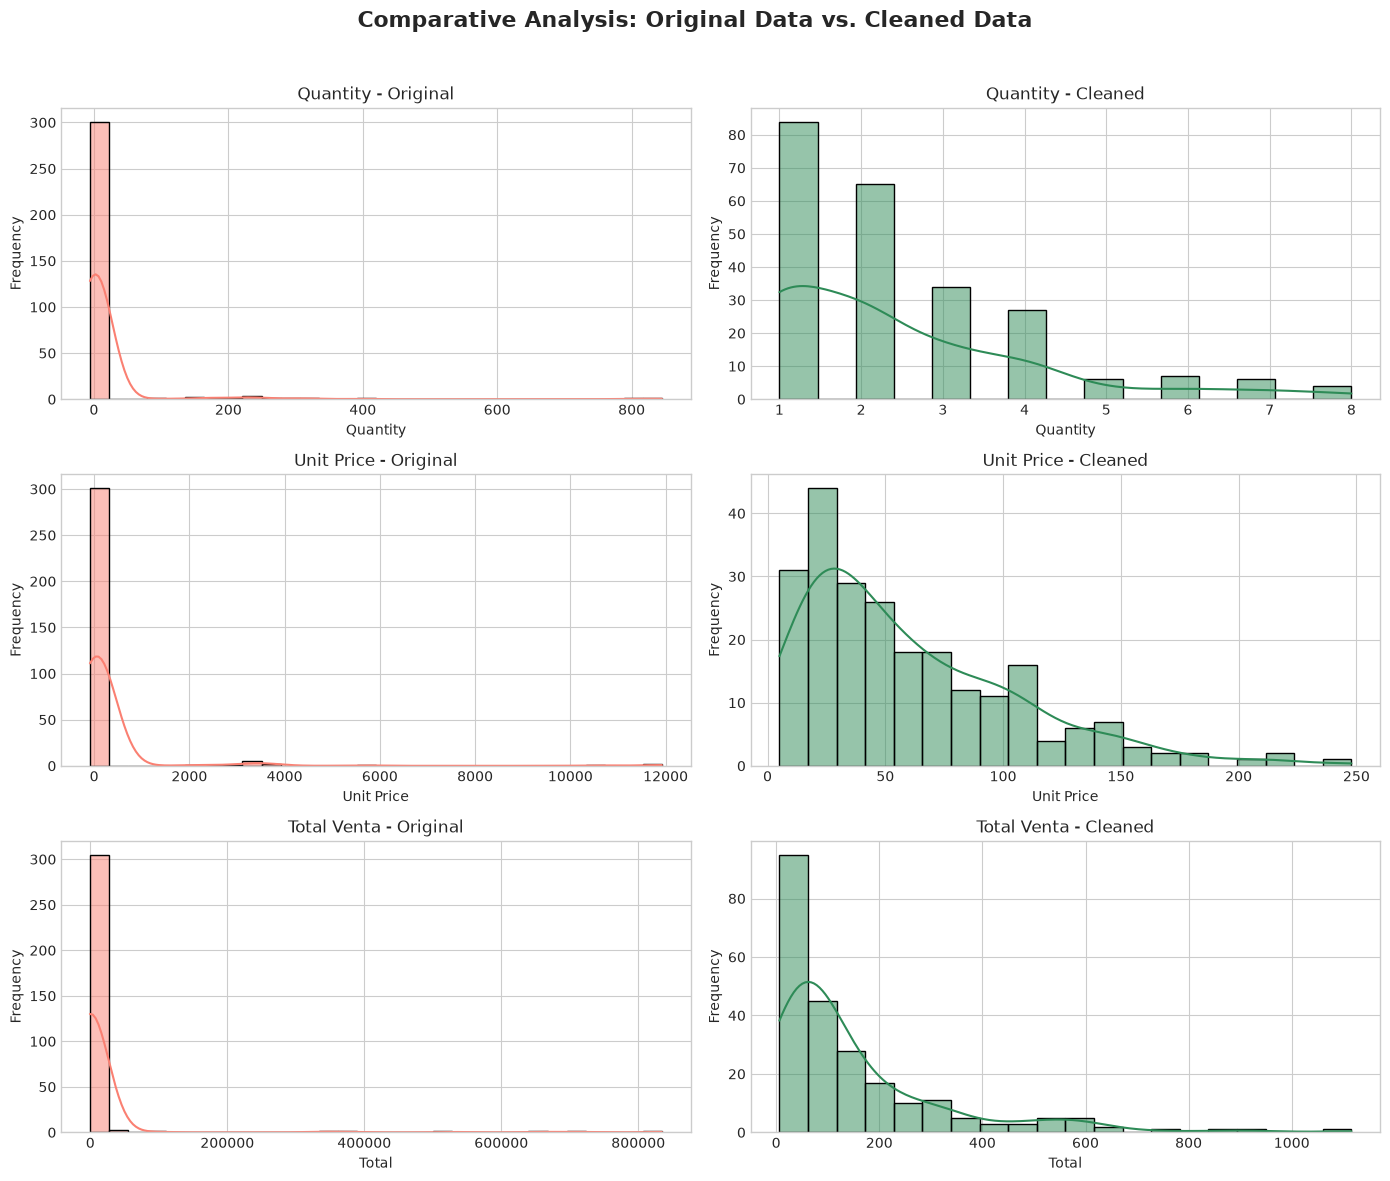

+ ---------------------------------------------------------
+ Time to process: 3.2927 seconds
+ =========================================================


In [112]:
# DATA CLEANING, 9. COMPARATIVE VISUALIZATIONS (BEFORE VS. AFTER)
# ===============================================================
tInit: float = time.time()

try:
  csl.SectionBegin("DATA CLEANING, COMPARATIVE VISUALIZATIONS", 0)
  csl.SectionBreak(0, 0)

  # Configure visual style
  plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
  fig, axes = plt.subplots(3, 2, figsize=(14, 12))
  fig.suptitle('Comparative Analysis: Original Data vs. Cleaned Data', fontsize=16, fontweight='bold', y=0.98)

  # 1. Quantity
  sns.histplot(dfSrc['cantidad'].dropna(), ax=axes[0, 0], color='salmon', bins=30, kde=True)
  axes[0, 0].set_title('Quantity - Original')
  axes[0, 0].set_xlabel('Quantity')
  axes[0, 0].set_ylabel('Frequency')

  sns.histplot(dfCln['cantidad'], ax=axes[0, 1], color='seagreen', bins=15, kde=True)
  axes[0, 1].set_title('Quantity - Cleaned')
  axes[0, 1].set_xlabel('Quantity')
  axes[0, 1].set_ylabel('Frequency')

  # 2. Unit Price
  sns.histplot(dfSrc['precio_unitario'].dropna(), ax=axes[1, 0], color='salmon', bins=30, kde=True)
  axes[1, 0].set_title('Unit Price - Original')
  axes[1, 0].set_xlabel('Unit Price')
  axes[1, 0].set_ylabel('Frequency')

  sns.histplot(dfCln['precio_unitario'], ax=axes[1, 1], color='seagreen', bins=20, kde=True)
  axes[1, 1].set_title('Unit Price - Cleaned')
  axes[1, 1].set_xlabel('Unit Price')
  axes[1, 1].set_ylabel('Frequency')

  # 3. Importe Total
  sns.histplot(dfSrc['total'].dropna(), ax=axes[2, 0], color='salmon', bins=30, kde=True)
  axes[2, 0].set_title('Total Venta - Original')
  axes[2, 0].set_xlabel('Total')
  axes[2, 0].set_ylabel('Frequency')

  sns.histplot(dfCln['total'], ax=axes[2, 1], color='seagreen', bins=20, kde=True)
  axes[2, 1].set_title('Total Venta - Cleaned')
  axes[2, 1].set_xlabel('Total')
  axes[2, 1].set_ylabel('Frequency')

  plt.tight_layout(rect=[0, 0, 1, 0.96])
  
  # Optional: save figure to disk if a figures directory exists
  figPath = figPath / 'comparativa_limpieza.png'
  figPath.parent.mkdir(parents=True, exist_ok=True)
  plt.savefig(figPath, dpi=300, bbox_inches='tight')
  print(f"Visualizations generated and saved successfully to:\n{figPath}")

  plt.show()

except Exception as e:
  csl.SectionErrEndAndExit({
    'bOk': False,
    'err': { 'code': 500, 'whre': sys._getframe(0).f_code.co_name, 'mssg': e.args[0] }
  }, tInit)

csl.SectionBreak(0, 0)
tEnd: float = time.time()
print(f"+ Time to process: {tEnd - tInit:.4f} seconds")
csl.SectionEnd(0)